## Importation des bibliothèques et vérification de l'environnement

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("Bibliothèques importées avec succès !")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version : {np.__version__}")

Bibliothèques importées avec succès !
Pandas version : 2.2.2
NumPy version : 2.0.2


## Chargement des données

In [3]:
df = pd.read_excel('TRAFIC_POINT_2023.xlsx', sheet_name='TRAFIC_POINT_2023')

print(f"Nombre de lignes : {df.shape[0]}")
print(f"Nombre de colonnes : {df.shape[1]}")
print(f"\nColonnes disponibles :")
print(df.columns.tolist())

Nombre de lignes : 617
Nombre de colonnes : 21

Colonnes disponibles :
['ROUTE', 'PR', 'ABS', 'CUMUL', 'ID_ROUTE', 'PR_DEB', 'PR_FIN', 'CATEGORIE', 'SECTION_IN', 'ID_TRAFIC', 'ID_SITE', 'NOM_SITE', 'LIEU', 'TYPE', 'CPTGE_YEAR', 'VALUE_TYPE', 'MJA_TV', 'MJA_PL', 'P_PL', 'X', 'Y']


## Exploration et compréhension des données

In [5]:
print("=== Aperçu des données ===")
print(df.head())

print("\n=== Types de données ===")
print(df.dtypes)

print("\n=== Valeurs manquantes ===")
print(df.isnull().sum())

print("\n=== Statistiques générales ===")
print(df[['MJA_TV', 'MJA_PL', 'P_PL']].describe())

=== Aperçu des données ===
      ROUTE  PR  ABS  CUMUL ID_ROUTE  PR_DEB  PR_FIN  CATEGORIE SECTION_IN  \
0  45 D0002   1  792   1633       D2     0+0   1+914          3        2_2   
1  45 D0002   3  215   3075       D2   1+956   4+242          4        2_3   
2  45 D0002   6  733   6467       D2   4+280  15+248          4        2_8   
3  45 D0002  17    0  16707       D2  15+249  19+950          4       2_12   
4  45 D0003   3    0   2278       D3     0+0   7+596          4        3_0   

      ID_TRAFIC  ...                              NOM_SITE  \
0  IDT_001_2023  ...      D0002_PR001+0792_Meung-sur-Loire   
1  IDT_002_2023  ...            D0002_PR003+0215_Le Bardon   
2  IDT_003_2023  ...               D0002_PR006+0733_Baccon   
3  IDT_004_2023  ...         D0002_PR017+0000_Charsonville   
4  IDT_005_2023  ...  D0003_PR003+0000_Huisseau-sur-Mauves   

                                                LIEU        TYPE CPTGE_YEAR  \
0                                    Meung-sur-Loire

## Nettoyage des données

In [7]:
print("=== Avant le nettoyage ===")
print(f"Valeurs manquantes MJA_PL : {df['MJA_PL'].isnull().sum()}")
print(f"Valeurs manquantes P_PL : {df['P_PL'].isnull().sum()}")

# Remplacement des valeurs manquantes par 0
df['MJA_PL'] = df['MJA_PL'].fillna(0)
df['P_PL'] = df['P_PL'].fillna(0)

# Nettoyage ID_ROUTE
df['ID_ROUTE'] = df['ID_ROUTE'].str.strip()

# Labels catégories lisibles
cat_labels = {
    1: 'Cat.1 — Structurante',
    2: 'Cat.2 — Principale',
    3: 'Cat.3 — Secondaire',
    4: 'Cat.4 — Locale'
}
df['CAT_LABEL'] = df['CATEGORIE'].map(cat_labels)

print("\n=== Après le nettoyage ===")
print(f"Valeurs manquantes MJA_PL : {df['MJA_PL'].isnull().sum()}")
print(f"Valeurs manquantes P_PL : {df['P_PL'].isnull().sum()}")
print(f"\nRépartition par catégorie :")
print(df['CAT_LABEL'].value_counts())
print(f"\nRépartition par type de poste :")
print(df['TYPE'].value_counts())
print("\nLes données sont nettoyées et sont prêtes pour l'analyse !")

=== Avant le nettoyage ===
Valeurs manquantes MJA_PL : 0
Valeurs manquantes P_PL : 0

=== Après le nettoyage ===
Valeurs manquantes MJA_PL : 0
Valeurs manquantes P_PL : 0

Répartition par catégorie :
CAT_LABEL
Cat.4 — Locale          430
Cat.2 — Principale       71
Cat.1 — Structurante     67
Cat.3 — Secondaire       49
Name: count, dtype: int64

Répartition par type de poste :
TYPE
Temporaire    500
Permanent     117
Name: count, dtype: int64

Les données sont nettoyées et sont prêtes pour l'analyse !


## Axes les plus chargés

In [8]:
#15 axes les plus chargés
print("=== Top 15 Axes les plus chargés ===\n")
top15 = df.nlargest(15, 'MJA_TV')[['LIEU', 'MJA_TV', 'P_PL', 'TYPE', 'CAT_LABEL']]
top15 = top15.reset_index(drop=True)
top15.index += 1  # Commencer à 1
print(top15.to_string())

print(f"\n Axe le plus chargé : {df.loc[df['MJA_TV'].idxmax(), 'LIEU']}")
print(f"   MJA : {df['MJA_TV'].max():,} véhicules/jour")
print(f"   % PL : {df.loc[df['MJA_TV'].idxmax(), 'P_PL']}%")
print(f"   Type : {df.loc[df['MJA_TV'].idxmax(), 'TYPE']}")

print(f"\n Axe le plus logistique (% PL max) :")
print(f"   Lieu : {df.loc[df['P_PL'].idxmax(), 'LIEU']}")
print(f"   % PL : {df['P_PL'].max()}%")
print(f"   MJA : {df.loc[df['P_PL'].idxmax(), 'MJA_TV']:,} véhicules/jour")

=== Top 15 Axes les plus chargés ===

                                                                             LIEU  MJA_TV  P_PL       TYPE             CAT_LABEL
1                       Orléans (Fosse Bénate) - Saran (accés D2701 - début D520)   53979   9.5  Permanent  Cat.1 — Structurante
2             Saint-Jean-de-Braye (Echangeur avec D2152) - Orléans (Fosse Bénate)   51484   9.2  Permanent  Cat.1 — Structurante
3                       Saran (Accès D2701 - fin D2060) - Saint-Jean-de-la-Ruelle   41440   4.2  Permanent  Cat.1 — Structurante
4   Chécy (Echangeur D8 - accés ZAC) - Saint-Jean-de-Braye (Echangeur avec D2152)   40386   9.7  Permanent  Cat.1 — Structurante
5                            Saint-Jean-de-la-Ruelle - Orléans (Pont de l'Europe)   38029   5.8  Permanent  Cat.1 — Structurante
6                   Agglomération de Montargis (D2060 nord - Giratoire cacahuète)   35204  10.5  Permanent  Cat.1 — Structurante
7                  De la sortie péage A10 nord au giratoire

## Détection des anomalies

In [9]:
# Méthode deux écarts-types
print("=== Détection automatique des anomalies ===\n")

# Calcul des seuils statistiques
moyenne = df['MJA_TV'].mean()
std = df['MJA_TV'].std()
seuil_haut = moyenne + 2 * std
seuil_bas = moyenne - 2 * std

print(f"Moyenne MJA : {moyenne:.0f} véh/jour")
print(f"Écart-type  : {std:.0f} véh/jour")
print(f"Seuil haut  : {seuil_haut:.0f} véh/jour (+2σ)")
print(f"Seuil bas   : {max(0, seuil_bas):.0f} véh/jour (-2σ)")

# Identification des anomalies
anomalies_haut = df[df['MJA_TV'] > seuil_haut]
anomalies_bas = df[df['MJA_TV'] < max(0, seuil_bas)]

print(f"\n  Anomalies hautes (trafic exceptionnel) : {len(anomalies_haut)}")
print(anomalies_haut[['LIEU', 'MJA_TV', 'TYPE']].to_string(index=False))

print(f"\n  Anomalies basses (trafic très faible) : {len(anomalies_bas)}")
print(anomalies_bas[['LIEU', 'MJA_TV', 'TYPE']].head(10).to_string(index=False))

# Création de la colonne anomalie
df['Anomalie'] = 'Normal'
df.loc[df['MJA_TV'] > seuil_haut, 'Anomalie'] = 'Haut'
df.loc[df['MJA_TV'] < max(0, seuil_bas), 'Anomalie'] = 'Bas'

print(f"\n Colonne Anomalie ajoutée au dataframe !")
print(df['Anomalie'].value_counts())

=== Détection automatique des anomalies ===

Moyenne MJA : 2983 véh/jour
Écart-type  : 5537 véh/jour
Seuil haut  : 14058 véh/jour (+2σ)
Seuil bas   : 0 véh/jour (-2σ)

  Anomalies hautes (trafic exceptionnel) : 17
                                                                         LIEU  MJA_TV      TYPE
                 Giratoire cacahuète Zone commerciale de Checy (D308) - D2060   15099 Permanent
                    Saran (Accès D2701 - fin D2060) - Saint-Jean-de-la-Ruelle   41440 Permanent
                         Saint-Jean-de-la-Ruelle - Orléans (Pont de l'Europe)   38029 Permanent
                                                        Liaison Ormes - Saran   27140 Permanent
                                                              Pont de Jargeau   15952 Permanent
                            Pont de Sully-sur-Loire  (des D60-D119 à la D951)   16194 Permanent
                Agglomération de Montargis (D2060 nord - Giratoire cacahuète)   35204 Permanent
                  

## Visualisation top 15 axes

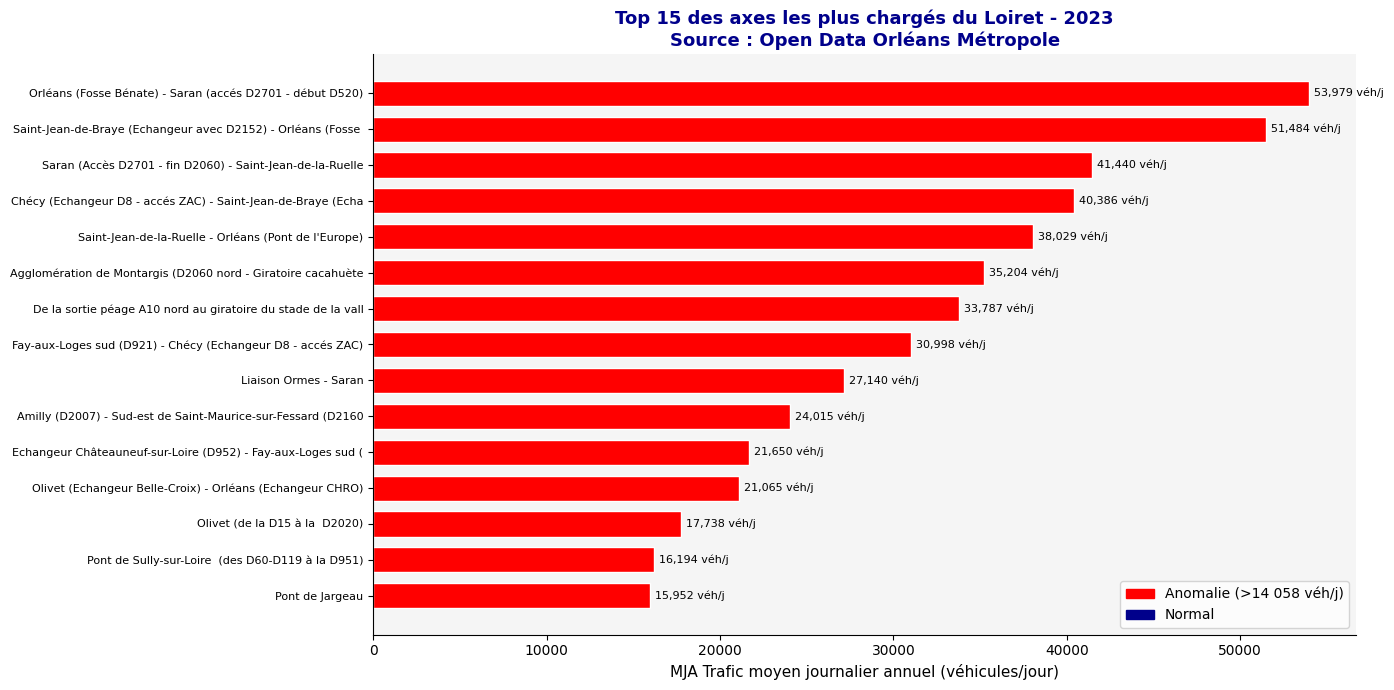

 Graphique 1 


In [13]:
fig, ax = plt.subplots(figsize=(14, 7))

top15 = df.nlargest(15, 'MJA_TV')
colors = ['red' if v == 'Haut' else 'darkblue'
          for v in top15['Anomalie']]

bars = ax.barh(range(15), top15['MJA_TV'].values,
               color=colors, edgecolor='white', height=0.7)

ax.set_yticks(range(15))
ax.set_yticklabels([l[:60] for l in top15['LIEU'].values], fontsize=8)
ax.set_xlabel('MJA Trafic moyen journalier annuel (véhicules/jour)', fontsize=11)
ax.set_title('Top 15 des axes les plus chargés du Loiret - 2023\n'
             'Source : Open Data Orléans Métropole',
             fontsize=13, fontweight='bold', color='darkblue')

for bar, val in zip(bars, top15['MJA_TV'].values):
    ax.text(bar.get_width() + 300,
            bar.get_y() + bar.get_height()/2,
            f'{val:,} véh/j', va='center', fontsize=8)

ax.invert_yaxis()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_facecolor('whitesmoke')

from matplotlib.patches import Patch
legend = [Patch(color='red', label='Anomalie (>14 058 véh/j)'),
          Patch(color='darkblue', label='Normal')]
ax.legend(handles=legend, fontsize=10)

plt.tight_layout()
plt.savefig('top15_axes.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Graphique 1 ")

## Visualisation détection des anomalies

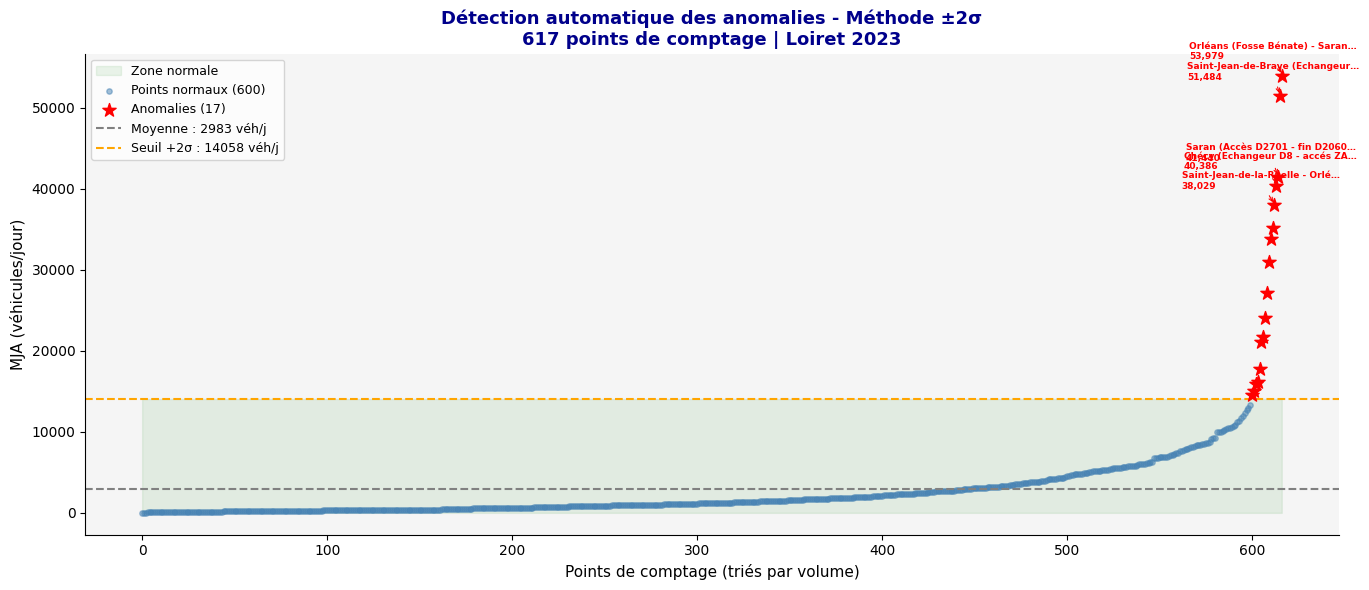

 Graphique 2 


In [14]:
fig, ax = plt.subplots(figsize=(14, 6))

df_sorted = df.sort_values('MJA_TV').reset_index(drop=True)

# Points normaux
normal = df_sorted[df_sorted['Anomalie'] == 'Normal']
anom = df_sorted[df_sorted['Anomalie'] == 'Haut']

ax.fill_between(range(len(df_sorted)), 0, seuil_haut,
                alpha=0.08, color='green', label='Zone normale')
ax.scatter(normal.index, normal['MJA_TV'],
           color='steelblue', s=15, alpha=0.5,
           label=f'Points normaux ({len(normal)})')
ax.scatter(anom.index, anom['MJA_TV'],
           color='red', s=100, zorder=5, marker='*',
           label=f'Anomalies ({len(anom)})')
ax.axhline(moyenne, color='gray', linestyle='--', lw=1.5,
           label=f'Moyenne : {moyenne:.0f} véh/j')
ax.axhline(seuil_haut, color='orange', linestyle='--', lw=1.5,
           label=f'Seuil +2σ : {seuil_haut:.0f} véh/j')

# Annoter les 5 plus grandes anomalies
for _, row in anom.nlargest(5, 'MJA_TV').iterrows():
    ax.annotate(f"{row['LIEU'][:30]}…\n{row['MJA_TV']:,}",
                xy=(row.name, row['MJA_TV']),
                xytext=(row.name - 50, row['MJA_TV'] + 2000),
                fontsize=6.5, color='red', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='red', lw=0.8))

ax.set_xlabel('Points de comptage (triés par volume)', fontsize=11)
ax.set_ylabel('MJA (véhicules/jour)', fontsize=11)
ax.set_title('Détection automatique des anomalies - Méthode ±2σ\n'
             '617 points de comptage | Loiret 2023',
             fontsize=13, fontweight='bold', color='darkblue')
ax.legend(fontsize=9, loc='upper left')
ax.set_facecolor('whitesmoke')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('anomalies_detection.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Graphique 2 ")

## Visualisation des axes logistiques (Poids lourds)

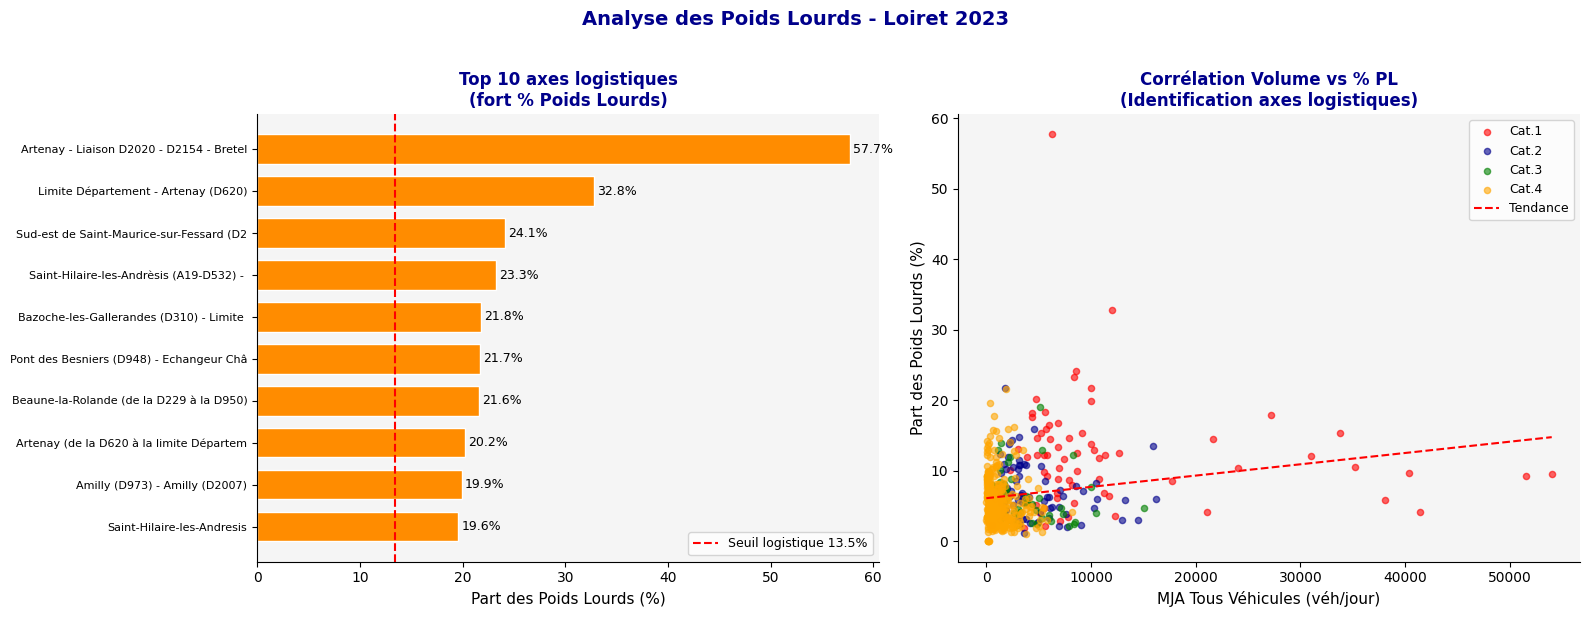

Graphique 3 


In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Graphique gauche : Top 10 % PL ---
df_pl = df[df['P_PL'] > 0]
top_pl = df_pl.nlargest(10, 'P_PL')
seuil_pl = df_pl['P_PL'].mean() + 1.5 * df_pl['P_PL'].std()

colors_pl = ['darkorange' if p > seuil_pl else 'steelblue'
             for p in top_pl['P_PL']]
bars = ax1.barh(range(10), top_pl['P_PL'].values,
                color=colors_pl, edgecolor='white', height=0.7)
ax1.set_yticks(range(10))
ax1.set_yticklabels([l[:40] for l in top_pl['LIEU'].values], fontsize=8)
ax1.set_xlabel('Part des Poids Lourds (%)', fontsize=11)
ax1.set_title('Top 10 axes logistiques\n(fort % Poids Lourds)',
              fontsize=12, fontweight='bold', color='darkblue')
ax1.axvline(seuil_pl, color='red', linestyle='--', lw=1.5,
            label=f'Seuil logistique {seuil_pl:.1f}%')
for bar, val in zip(bars, top_pl['P_PL'].values):
    ax1.text(bar.get_width() + 0.3,
             bar.get_y() + bar.get_height()/2,
             f'{val:.1f}%', va='center', fontsize=9)
ax1.invert_yaxis()
ax1.legend(fontsize=9)
ax1.set_facecolor('whitesmoke')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- Graphique droite : Corrélation MJA vs % PL ---
colors_cat = {1:'red', 2:'darkblue', 3:'green', 4:'orange'}
for cat in [1, 2, 3, 4]:
    subset = df[df['CATEGORIE'] == cat]
    ax2.scatter(subset['MJA_TV'], subset['P_PL'],
                color=colors_cat[cat], s=20, alpha=0.6,
                label=f'Cat.{cat}')

# Ligne de tendance
z = np.polyfit(df_pl['MJA_TV'], df_pl['P_PL'], 1)
p_fit = np.poly1d(z)
xl = np.linspace(df['MJA_TV'].min(), df['MJA_TV'].max(), 100)
ax2.plot(xl, p_fit(xl), 'red', linestyle='--', lw=1.5, label='Tendance')

ax2.set_xlabel('MJA Tous Véhicules (véh/jour)', fontsize=11)
ax2.set_ylabel('Part des Poids Lourds (%)', fontsize=11)
ax2.set_title('Corrélation Volume vs % PL\n(Identification axes logistiques)',
              fontsize=12, fontweight='bold', color='darkblue')
ax2.legend(fontsize=9)
ax2.set_facecolor('whitesmoke')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.suptitle('Analyse des Poids Lourds - Loiret 2023',
             fontsize=14, fontweight='bold', color='darkblue', y=1.02)
plt.tight_layout()
plt.savefig('axes_logistiques.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graphique 3 ")

## Visualisation Distribution par catégorie

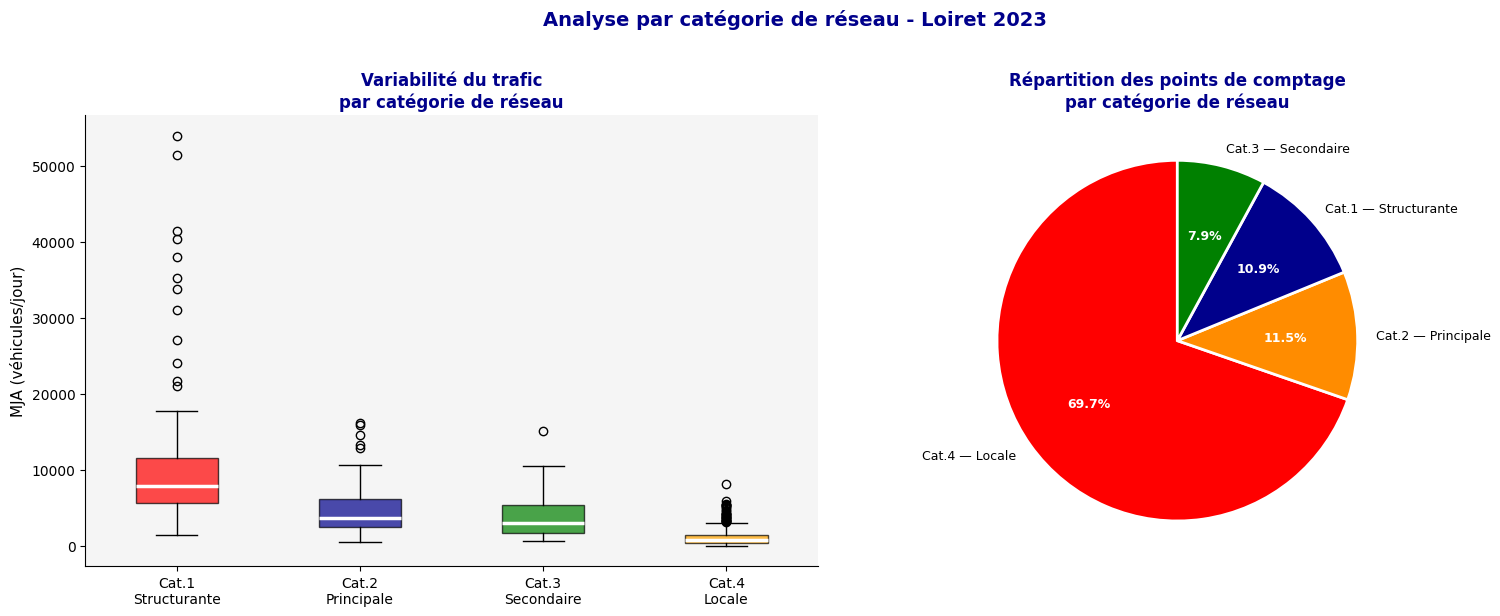

Graphique 4 


In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Graphique gauche : Boxplot ---
data_box = [df[df['CATEGORIE'] == c]['MJA_TV'].values
            for c in [1, 2, 3, 4]]
colors_box = ['red', 'darkblue', 'green', 'orange']
bp = ax1.boxplot(data_box, patch_artist=True,
                 medianprops=dict(color='white', linewidth=2.5))
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax1.set_xticklabels(['Cat.1\nStructurante', 'Cat.2\nPrincipale',
                     'Cat.3\nSecondaire', 'Cat.4\nLocale'], fontsize=10)
ax1.set_ylabel('MJA (véhicules/jour)', fontsize=11)
ax1.set_title('Variabilité du trafic\npar catégorie de réseau',
              fontsize=12, fontweight='bold', color='darkblue')
ax1.set_facecolor('whitesmoke')
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# --- Graphique droite : Nombre de points par catégorie ---
cat_counts = df['CAT_LABEL'].value_counts()
colors_pie = ['red', 'darkorange', 'darkblue', 'green']
wedges, texts, autotexts = ax2.pie(
    cat_counts.values,
    labels=cat_counts.index,
    autopct='%1.1f%%',
    colors=colors_pie,
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for text in texts:
    text.set_fontsize(9)
for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax2.set_title('Répartition des points de comptage\npar catégorie de réseau',
              fontsize=12, fontweight='bold', color='darkblue')

plt.suptitle('Analyse par catégorie de réseau - Loiret 2023',
             fontsize=14, fontweight='bold', color='darkblue', y=1.02)
plt.tight_layout()
plt.savefig('distribution_categories.png', dpi=150, bbox_inches='tight')
plt.show()
print("Graphique 4 ")

## Carte interactive avec Folium

In [18]:
!pip install folium -q

import folium

print("Création de la carte interactive...")

# Carte centrée sur Orléans
m = folium.Map(location=[47.9, 2.35], zoom_start=10,
               tiles='CartoDB positron')

# Fonction couleur selon MJA
def get_color(mja, anomalie):
    if anomalie == 'Haut':
        return 'red'
    elif mja > 10000:
        return 'orange'
    elif mja > 3000:
        return 'blue'
    else:
        return 'green'

def get_radius(mja):
    if mja > 30000: return 12
    elif mja > 15000: return 9
    elif mja > 5000: return 6
    else: return 4

# Ajouter les 617 points
for _, row in df.iterrows():
    color = get_color(row['MJA_TV'], row['Anomalie'])
    radius = get_radius(row['MJA_TV'])

    popup_html = f"""
    <div style='font-family:Arial; min-width:200px;'>
        <b style='color:darkblue;'>{row['LIEU'][:50]}</b><br>
        <hr style='margin:4px 0;'>
        <b>MJA :</b> {row['MJA_TV']:,} véh/jour<br>
        <b>% PL :</b> {row['P_PL']:.1f}%<br>
        <b>Type :</b> {row['TYPE']}<br>
        <b>Catégorie :</b> {row['CAT_LABEL']}<br>
        <b>Statut :</b> {row['Anomalie']}
    </div>
    """

    folium.CircleMarker(
        location=[row['Y'], row['X']],
        radius=radius,
        color='white',
        weight=1,
        fill=True,
        fill_color=color,
        fill_opacity=0.85,
        popup=folium.Popup(popup_html, max_width=250),
        tooltip=f"{row['LIEU'][:35]} | {row['MJA_TV']:,} véh/j"
    ).add_to(m)

# Légende
legend_html = '''
<div style="position: fixed; bottom: 30px; left: 20px;
     z-index: 1000; background-color: white; padding: 12px;
     border-radius: 8px; box-shadow: 0 2px 8px rgba(0,0,0,0.3);
     font-family: Arial; font-size: 11px;">
    <b style="color:darkblue;">Niveau de trafic (MJA)</b><br><br>
    <span style="color:red;">● </span> Anomalie (>14 058 véh/j)<br>
    <span style="color:orange;">● </span> Fort (10-14 058 véh/j)<br>
    <span style="color:blue;">● </span> Moyen (3-10 000 véh/j)<br>
    <span style="color:green;">● </span> Faible (<3 000 véh/j)
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))

# Sauvegarder
m.save('carte_trafic_orleans.html')
print(f"Carte créée avec {len(df)} points")
print("Téléchargeons le fichier carte_trafic_orleans.html")
m

Création de la carte interactive...
Carte créée avec 617 points
Téléchargeons le fichier carte_trafic_orleans.html


## Rapport de conclusions

In [19]:
print("=" * 60)
print("   RAPPORT D'ANALYSE DU TRAFIC ROUTIER LOIRET 2023")
print("   Réalisé par : Célestine LENO")
print("=" * 60)

print("\n 1. CONTEXTE")
print("-" * 40)
print(f"Source       : Open Data Orléans Métropole / Dept. Loiret")
print(f"Données      : {len(df)} points de comptage - Année 2023")
print(f"Postes perm. : {len(df[df['TYPE']=='Permanent'])} | Temporaires : {len(df[df['TYPE']=='Temporaire'])}")

print("\n 2. RÉSULTATS CLÉS")
print("-" * 40)
print(f"MJA moyenne  : {df['MJA_TV'].mean():.0f} véhicules/jour")
print(f"MJA médiane  : {df['MJA_TV'].median():.0f} véhicules/jour")
print(f"MJA maximum  : {df['MJA_TV'].max():,} véh/j")
print(f"  {df.loc[df['MJA_TV'].idxmax(), 'LIEU']}")
print(f"% PL maximum : {df['P_PL'].max()}%")
print(f"  {df.loc[df['P_PL'].idxmax(), 'LIEU']}")

print("\n 3. ANOMALIES DÉTECTÉES (méthode plus ou moins deux écarts-types)")
print("-" * 40)
anomalies = df[df['Anomalie'] == 'Haut']
print(f"Seuil        : {seuil_haut:.0f} véhicules/jour")
print(f"Anomalies    : {len(anomalies)} points sur {len(df)}")
print(f"Localisation : Majoritairement autour d'Orléans et Montargis")
for _, row in anomalies.nlargest(5, 'MJA_TV').iterrows():
    print(f"  {row['LIEU'][:50]} : {row['MJA_TV']:,} véh/j")

print("\n 4. AXES LOGISTIQUES (fort % PL)")
print("-" * 40)
df_pl = df[df['P_PL'] > 0]
seuil_pl = df_pl['P_PL'].mean() + 1.5 * df_pl['P_PL'].std()
axes_log = df[df['P_PL'] > seuil_pl]
print(f"Seuil PL     : {seuil_pl:.1f}%")
print(f"Axes identif.: {len(axes_log)} points")
for _, row in axes_log.nlargest(3, 'P_PL').iterrows():
    print(f"  {row['LIEU'][:50]} : {row['P_PL']:.1f}% PL")

print("\n 5. RECOMMANDATIONS POUR L'AUTOMATISATION SYMART")
print("-" * 40)
print("""
   R1 - Surveillance prioritaire des 17 axes anomaliques
     Mettre en place des alertes automatiques si MJA > 14 058

   R2 - Suivi renforcé des axes logistiques
     Surveiller l'usure chaussée sur les axes > 13.5% PL

   R3 - Consolidation des postes temporaires
     500 postes temporaires = données ponctuelles
     Prioriser la pose de capteurs permanents sur Cat.1

   R4 - Pipeline d'automatisation
     Ce script Python peut être exécuté automatiquement
       à chaque mise à jour des données open data
     Génération automatique des rapports et alertes
""")

print("=" * 60)
print("   MERCI ")
print("=" * 60)

   RAPPORT D'ANALYSE DU TRAFIC ROUTIER LOIRET 2023
   Réalisé par : Célestine LENO

 1. CONTEXTE
----------------------------------------
Source       : Open Data Orléans Métropole / Dept. Loiret
Données      : 617 points de comptage - Année 2023
Postes perm. : 117 | Temporaires : 500

 2. RÉSULTATS CLÉS
----------------------------------------
MJA moyenne  : 2983 véhicules/jour
MJA médiane  : 1203 véhicules/jour
MJA maximum  : 53,979 véh/j
  Orléans (Fosse Bénate) - Saran (accés D2701 - début D520)
% PL maximum : 57.7%
  Artenay - Liaison D2020 - D2154 - Bretelle A10

 3. ANOMALIES DÉTECTÉES (méthode plus ou moins deux écarts-types)
----------------------------------------
Seuil        : 14058 véhicules/jour
Anomalies    : 17 points sur 617
Localisation : Majoritairement autour d'Orléans et Montargis
  Orléans (Fosse Bénate) - Saran (accés D2701 - débu : 53,979 véh/j
  Saint-Jean-de-Braye (Echangeur avec D2152) - Orléa : 51,484 véh/j
  Saran (Accès D2701 - fin D2060) - Saint-Jean-de-l